# 비지도학습 기반 고객 세분화 분석 프로그램

**실습 과제 답안 노트북**  
데이터: `Mall_Customers.csv` (쇼핑몰 고객 200명)  
방법: **PCA 차원축소** + **K-Means 군집화**

이 노트북은 초보 기획자도 흐름을 따라갈 수 있도록, 단계별로 목적과 코드를 나눠 작성했습니다.


## 0. 전체 개발 순서와 단계별 목적

| 단계 | 할 일 | 목적 |
|------|--------|------|
| 1 | CSV 불러오기, 구조·자료형·결측치·기초통계 확인 | 데이터가 분석 가능한 상태인지 파악 |
| 2 | `CustomerID` 제외 | 단순 식별자라 군집 거리 계산에 쓰면 안 됨 |
| 3 | Age, Annual Income, Spending Score 선택 | 과제에서 지정한 분석 변수만 사용 |
| 4 | StandardScaler 표준화 | 나이·소득·점수의 단위가 달라 거리 왜곡을 막음 |
| 5 | PCA 2차원 축소, 설명 분산 비율 확인 | 시각화하고, 정보가 얼마나 남았는지 점검 |
| 6 | K=2~8 Inertia·실루엣 점수 계산 | 군집 수 후보를 수치로 비교 |
| 7 | 엘보우·실루엣 그래프 | 눈으로 적정 군집 수 판단 |
| 8 | 최종 K 선택 후 K-Means 학습 | 실제 세그먼트 부여 |
| 9 | PCA 산점도(군집별 색상) | 군집이 공간에서 어떻게 나뉘는지 확인 |
| 10 | 군집별 인원·평균 표 | 각 그룹의 실제 특성 수치화 |
| 11 | 특성 설명 및 고객 유형명 제안 | 데이터에 근거한 네이밍 |
| 12 | `customer_cluster_results.csv` 저장 | 후속 기획·마케팅에서 재사용 |
| 13 | 주요 그래프 PNG 저장 | 보고서·발표 자료로 활용 |

> **중요:** 군집 번호(0, 1, 2…)는 **우열이나 VIP 등급이 아닙니다.**  
> 단지 “서로 비슷한 고객끼리 묶인 그룹의 이름표”입니다.  
> 유형명과 수치는 **아래 코드를 실행한 결과**를 보고 제안합니다.


## 0-1. 필요 라이브러리 설치

아래 패키지가 없다면 주석을 해제하고 실행하세요.

```text
pip install pandas numpy matplotlib scikit-learn
```

- `pandas` : 표 형태 데이터 처리
- `numpy` : 수치 계산
- `matplotlib` : 그래프
- `scikit-learn` : StandardScaler, PCA, K-Means, 실루엣 점수


In [1]:
# 필요 시 아래 한 줄의 주석을 해제하고 실행합니다.
# %pip install pandas numpy matplotlib scikit-learn

# 코랩(Colab) 환경에서 한글 깨짐 방지를 위한 나눔 폰트 설치
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/u

## 0-2. 라이브러리 불러오기, 한글 폰트, 파일 경로

**파일 경로가 잘못되었을 때**
1. `Mall_Customers.csv`를 **이 노트북과 같은 폴더**에 둡니다.
2. Jupyter 왼쪽 폴더 트리에서 노트북이 있는 폴더를 연 뒤 실행합니다.
3. 그래도 안 되면 에러 메시지에 나오는 `현재 작업 폴더`를 확인하고, CSV를 그 위치로 옮기거나 `CSV_PATH`를 절대 경로로 바꿉니다.


In [2]:
# 데이터 처리
import pandas as pd
import numpy as np

# 시각화
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib import rcParams

# 전처리 / 비지도학습
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 파일 경로 처리
from pathlib import Path

# 표가 노트북에서 잘 보이도록 설정
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")


def set_korean_font():
    '''Windows/Mac/Linux/Colab에서 한글이 깨지지 않도록 폰트를 고릅니다.'''
    # Colab 환경에 설치된 나눔글꼴 폴더 전체를 탐색하여 폰트 매니저에 일괄 추가
    nanum_dirs = ['/usr/share/fonts/truetype/nanum']
    sys_fonts = fm.findSystemFonts(fontpaths=nanum_dirs)

    if sys_fonts:
        for f in sys_fonts:
            try:
                fm.fontManager.addfont(f)
            except Exception:
                pass
        rcParams["font.family"] = "NanumGothic"
    else:
        candidates = ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]
        available = {f.name for f in fm.fontManager.ttflist}
        for name in candidates:
            if name in available:
                rcParams["font.family"] = name
                break
    rcParams["axes.unicode_minus"] = False  # 마이너스 기호 깨짐 방지


set_korean_font()
plt.rcParams["figure.dpi"] = 110

# 노트북과 같은 폴더를 기준으로 CSV를 찾습니다.
BASE_DIR = Path.cwd()
CSV_PATH = BASE_DIR / "Mall_Customers.csv"

if not CSV_PATH.exists():
    # 현재 폴더에 없으면, 아래 파일명만 다시 한 번 확인합니다.
    CSV_PATH = Path("Mall_Customers.csv")

if not CSV_PATH.exists():
    raise FileNotFoundError(
        "Mall_Customers.csv 파일을 찾을 수 없습니다.\n"
        "해결 방법:\n"
        "  1) CSV 파일을 이 노트북과 같은 폴더에 복사하세요.\n"
        "  2) Jupyter의 작업 폴더를 노트북이 있는 위치로 바꾸세요.\n"
        f"  3) 현재 작업 폴더: {Path.cwd()}\n"
        "  4) 필요하면 CSV_PATH = Path(r'C:\\전체\\경로\\Mall_Customers.csv') 처럼 절대 경로를 지정하세요."
    )

print(f"작업 폴더: {BASE_DIR}")
print(f"데이터 파일: {CSV_PATH.resolve()}")

작업 폴더: /content
데이터 파일: /content/Mall_Customers.csv


## 1단계. CSV 불러오기와 데이터 탐색

구조, 자료형, 결측치, 기초통계량을 확인합니다.  
이상치나 결측이 많으면 이후 PCA·K-Means 결과가 왜곡될 수 있습니다.


In [3]:
# CSV 불러오기
raw_df = pd.read_csv(CSV_PATH)

print("=" * 60)
print("1) 데이터 구조 (행, 열)")
print("=" * 60)
print(f"행 개수: {raw_df.shape[0]}명")
print(f"열 개수: {raw_df.shape[1]}개")
print(f"컬럼 목록: {list(raw_df.columns)}")

print("\n" + "=" * 60)
print("2) 상위 5행")
print("=" * 60)
display(raw_df.head())

print("\n" + "=" * 60)
print("3) 자료형과 결측치 (info)")
print("=" * 60)
raw_df.info()

print("\n" + "=" * 60)
print("4) 컬럼별 결측치 개수")
print("=" * 60)
missing = raw_df.isnull().sum()
display(missing.to_frame(name="결측치 수"))

print("\n" + "=" * 60)
print("5) 수치형 변수 기초통계량")
print("=" * 60)
display(raw_df.describe())

print("\n" + "=" * 60)
print("6) 성별 분포")
print("=" * 60)
display(raw_df["Gender"].value_counts().to_frame(name="고객 수"))


1) 데이터 구조 (행, 열)
행 개수: 200명
열 개수: 5개
컬럼 목록: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

2) 상위 5행


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



3) 자료형과 결측치 (info)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

4) 컬럼별 결측치 개수


,결측치 수
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0



5) 수치형 변수 기초통계량


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00



6) 성별 분포


,고객 수
Gender,
Female,112
Male,88


## 2~3단계. 분석 변수 선택

- `CustomerID`는 고객을 구분하는 **일련번호**일 뿐, 소비 성향이 아닙니다.
- 값이 1, 2, 3…으로 커지므로 군집 거리에 넣으면 “나중에 가입한 고객”이 비슷하다고 오해할 수 있습니다.
- 과제 지정 변수 3개만 사용합니다: **Age, Annual Income (k$), Spending Score (1-100)**
- `Gender`는 군집 학습에는 넣지 않고, 나중에 해석용으로만 참고합니다.


In [4]:
# 원본은 나중에 결과 저장 때 다시 붙이기 위해 그대로 둡니다.
df = raw_df.copy()

# 분석에 사용할 3개 변수
FEATURE_COLS = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

# CustomerID, Gender는 학습에서 제외
X = df[FEATURE_COLS].copy()

print("학습에 사용할 변수:")
print(list(X.columns))
print(f"\n학습 데이터 크기: {X.shape}")
display(X.head())


학습에 사용할 변수:
['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

학습 데이터 크기: (200, 3)


,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


## 4단계. StandardScaler로 표준화

K-Means는 **유클리드 거리**로 비슷한 고객을 묶습니다.  
나이는 대략 18 ~ 70, 소득은 15 ~ 137, 소비점수는 1~100이라 단위가 다릅니다.  
표준화(평균 0, 표준편차 1)를 하지 않으면 값의 범위가 큰 변수가 군집을 지배합니다.


In [5]:
# 표준화: 각 변수를 (값 - 평균) / 표준편차로 변환
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 확인용 데이터프레임
X_scaled_df = pd.DataFrame(X_scaled, columns=FEATURE_COLS)

print("표준화 이후 평균(0에 가까워야 함) / 표준편차(1에 가까워야 함)")
display(X_scaled_df.agg(["mean", "std"]).round(4))
display(X_scaled_df.head())


표준화 이후 평균(0에 가까워야 함) / 표준편차(1에 가까워야 함)


,Age,Annual Income (k$),Spending Score (1-100)
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00


,Age,Annual Income (k$),Spending Score (1-100)
0,-1.42,-1.74,-0.43
1,-1.28,-1.74,1.20
2,-1.35,-1.70,-1.72
3,-1.14,-1.70,1.04
4,-0.56,-1.66,-0.40


## 5단계. PCA로 2차원 축소

3차원을 그대로 그리기는 어렵습니다. PCA는 정보의 손실을 최소화하며 주성분(PC1, PC2)을 만듭니다.  
**설명 분산 비율**이 높을수록, 2차원만 봐도 원래 데이터의 패턴을 잘 보존한 것입니다.


In [6]:
# 주성분 2개로 축소 (시각화 목적)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_
explained_df = pd.DataFrame(
    {
        "주성분": ["PC1", "PC2"],
        "설명 분산 비율": explained,
        "설명 분산 비율(%)": explained * 100,
    }
)
explained_df.loc["합계"] = [
    "PC1+PC2",
    explained.sum(),
    explained.sum() * 100,
]

print("PCA 설명 분산 비율")
display(explained_df)

# 각 주성분이 원래 변수와 얼마나 관련 있는지(로딩값)
loading_df = pd.DataFrame(
    pca.components_,
    columns=FEATURE_COLS,
    index=["PC1", "PC2"],
)
print("\n주성분 로딩값 (절댓값이 클수록 해당 변수의 영향이 큼)")
display(loading_df)

print("\n해석 힌트")
print("- PC1은 Age(+)와 Spending Score(-)의 대비가 큽니다. 나이가 많고 소비가 낮은 방향 vs 젊고 소비가 높은 방향")
print("- PC2는 Annual Income의 영향이 거의 전부입니다. 위/아래가 소득 차이를 의미합니다.")


PCA 설명 분산 비율


,주성분,설명 분산 비율,설명 분산 비율(%)
0,PC1,0.44,44.27
1,PC2,0.33,33.31
합계,PC1+PC2,0.78,77.57



주성분 로딩값 (절댓값이 클수록 해당 변수의 영향이 큼)


,Age,Annual Income (k$),Spending Score (1-100)
PC1,0.71,-0.05,-0.71
PC2,0.03,1.00,-0.04



해석 힌트
- PC1은 Age(+)와 Spending Score(-)의 대비가 큽니다. 나이가 많고 소비가 낮은 방향 vs 젊고 소비가 높은 방향
- PC2는 Annual Income의 영향이 거의 전부입니다. 위/아래가 소득 차이를 의미합니다.


## 6~7단계. 군집 수 평가 (Inertia, Silhouette)

- **Inertia(엘보우)**: 군집 내부 거리 합. 작을수록 뭉쳐 있지만, 군집을 늘리면 항상 줄어듭니다.  
  감소 폭이 급격히 완만해지는 **팔꿈치(elbow)** 지점을 찾습니다.
- **Silhouette Score**: -1 ~ 1. **1에 가까울수록** 군집이 잘 분리된 것입니다.

K를 2부터 8까지 바꿔 보고, 두 지표를 함께 보고 최종 K를 고릅니다.


In [7]:
# 같은 결과를 재현하기 위한 시드
RANDOM_STATE = 42
K_RANGE = range(2, 9)  # 2, 3, 4, 5, 6, 7, 8

inertia_list = []
silhouette_list = []

print("K | Inertia | Silhouette Score")
print("-" * 36)

for k in K_RANGE:
    # n_init=10: 초기 중심을 여러 번 뽑아 가장 좋은 결과를 사용
    kmeans_tmp = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    tmp_labels = kmeans_tmp.fit_predict(X_scaled)

    inertia = kmeans_tmp.inertia_
    sil = silhouette_score(X_scaled, tmp_labels)

    inertia_list.append(inertia)
    silhouette_list.append(sil)
    print(f"{k:>1} | {inertia:8.3f} | {sil:8.4f}")

metrics_df = pd.DataFrame(
    {
        "K": list(K_RANGE),
        "Inertia": inertia_list,
        "Silhouette Score": silhouette_list,
    }
)
display(metrics_df)

# 실루엣이 가장 높은 K를 참고값으로 출력 (최종 선택은 그래프와 함께 판단)
best_k_by_silhouette = int(metrics_df.loc[metrics_df["Silhouette Score"].idxmax(), "K"])
print(f"\n실루엣 점수가 가장 높은 K: {best_k_by_silhouette}")


K | Inertia | Silhouette Score
------------------------------------
2 |  389.386 |   0.3355
3 |  295.212 |   0.3578
4 |  205.225 |   0.4040
5 |  168.248 |   0.4166
6 |  133.868 |   0.4284
7 |  117.012 |   0.4172
8 |  103.873 |   0.4082


,K,Inertia,Silhouette Score
0,2,389.39,0.34
1,3,295.21,0.36
2,4,205.23,0.40
3,5,168.25,0.42
4,6,133.87,0.43
5,7,117.01,0.42
6,8,103.87,0.41



실루엣 점수가 가장 높은 K: 6


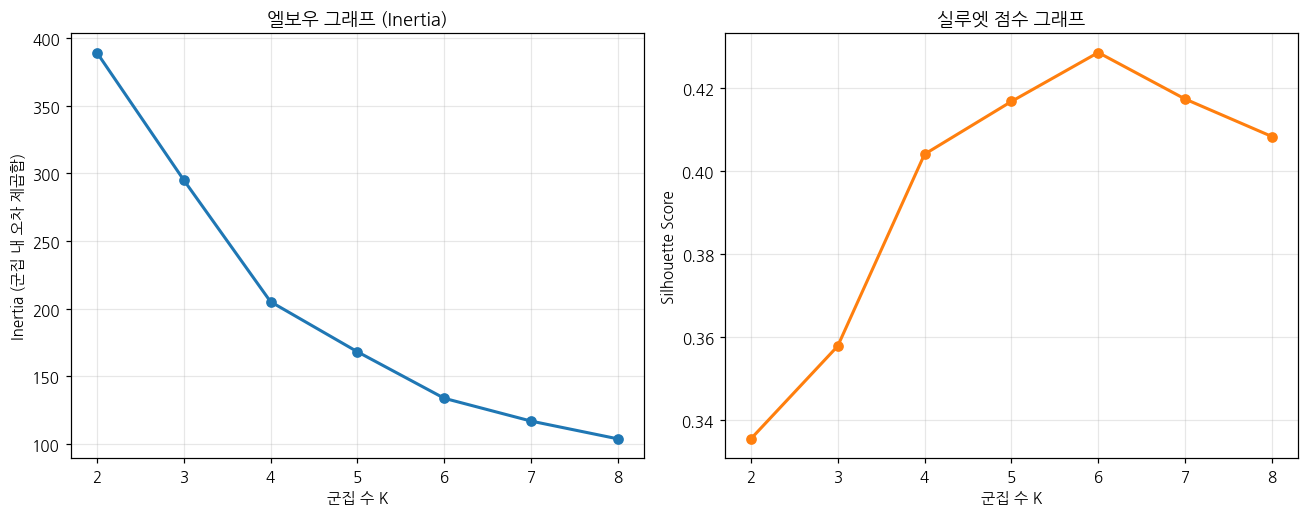

저장 완료: elbow_silhouette_plot.png


In [8]:
# 엘보우 그래프와 실루엣 점수 그래프를 나란히 그립니다.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# (1) 엘보우 그래프
axes[0].plot(list(K_RANGE), inertia_list, marker="o", linewidth=2)
axes[0].set_title("엘보우 그래프 (Inertia)")
axes[0].set_xlabel("군집 수 K")
axes[0].set_ylabel("Inertia (군집 내 오차 제곱합)")
axes[0].set_xticks(list(K_RANGE))
axes[0].grid(True, alpha=0.3)

# (2) 실루엣 점수 그래프
axes[1].plot(list(K_RANGE), silhouette_list, marker="o", color="tab:orange", linewidth=2)
axes[1].set_title("실루엣 점수 그래프")
axes[1].set_xlabel("군집 수 K")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(K_RANGE))
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
elbow_path = BASE_DIR / "elbow_silhouette_plot.png"
fig.savefig(elbow_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"저장 완료: {elbow_path.name}")


## 8단계. 최종 군집 수 선택 후 K-Means 학습

실행 결과를 보면 실루엣 점수는 **K=6에서 가장 높고**, 엘보우도 4~6 부근에서 감소 폭이 완만해집니다.  
그래서 이 답안에서는 **최종 군집 수 K=6**을 선택합니다.

K=5도 해석이 간단해서 실무에서 자주 쓰이지만, 이 데이터·이 변수 조합에서는 K=6이 분리 품질이 더 좋습니다.


In [9]:
# 최종 군집 수
FINAL_K = 6

final_kmeans = KMeans(n_clusters=FINAL_K, random_state=RANDOM_STATE, n_init=10)
cluster_labels = final_kmeans.fit_predict(X_scaled)

# 원본 데이터에 군집 번호와 PCA 좌표를 붙입니다.
df["Cluster"] = cluster_labels
df["PC1"] = X_pca[:, 0]
df["PC2"] = X_pca[:, 1]

print(f"최종 K-Means 학습 완료 (K={FINAL_K})")
print(f"Inertia: {final_kmeans.inertia_:.3f}")
print(f"Silhouette Score: {silhouette_score(X_scaled, cluster_labels):.4f}")

print("\n군집별 고객 수")
cluster_counts = df["Cluster"].value_counts().sort_index().rename("고객 수")
display(cluster_counts.to_frame())

print("\n참고: 군집 번호 0~5는 우수/불량 등급이 아닙니다. 단순 그룹 이름표입니다.")


최종 K-Means 학습 완료 (K=6)
Inertia: 133.868
Silhouette Score: 0.4284

군집별 고객 수


,고객 수
Cluster,
0,45
1,39
2,33
3,39
4,23
5,21



참고: 군집 번호 0~5는 우수/불량 등급이 아닙니다. 단순 그룹 이름표입니다.


## 9단계. PCA 산점도 (군집별 색상)

점이 같은 색끼리 모여 있을수록 군집화가 잘 된 것입니다.  
겹치는 부분이 있어도 정상입니다. PCA가 3차원 정보를 2차원으로 압축했기 때문입니다.


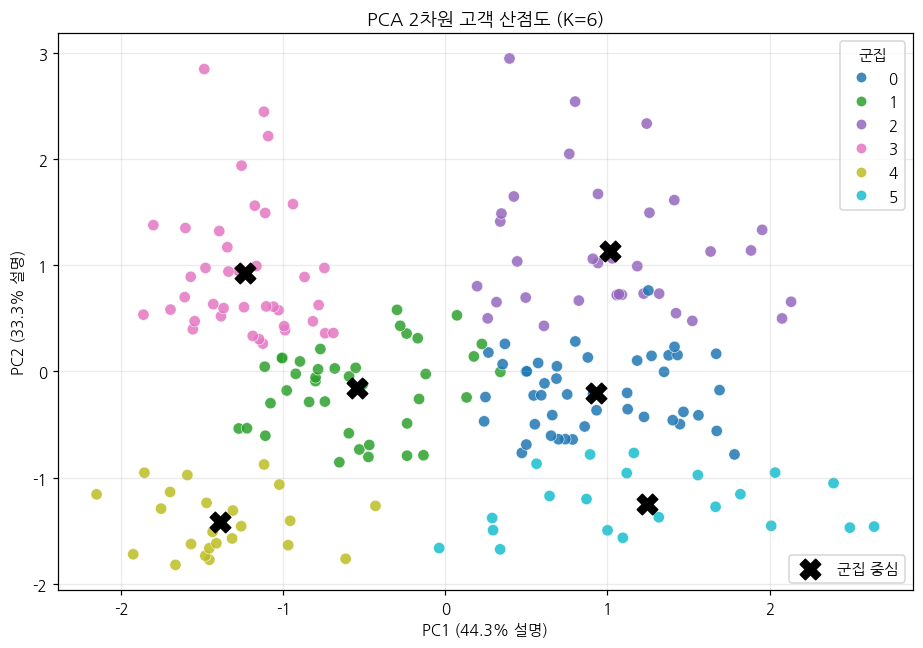

저장 완료: pca_cluster_scatter.png


In [10]:
fig, ax = plt.subplots(figsize=(8.5, 6))

# 군집마다 다른 색으로 산점도
scatter = ax.scatter(
    df["PC1"],
    df["PC2"],
    c=df["Cluster"],
    cmap="tab10",
    s=55,
    alpha=0.85,
    edgecolors="white",
    linewidths=0.4,
)

# PCA 공간에서의 군집 중심 (학습은 표준화 공간에서 했지만, 시각화는 PCA 좌표를 사용)
centers_scaled = final_kmeans.cluster_centers_
centers_pca = pca.transform(centers_scaled)
ax.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    s=180,
    c="black",
    marker="X",
    label="군집 중심",
    zorder=5,
)

ax.set_title(f"PCA 2차원 고객 산점도 (K={FINAL_K})")
ax.set_xlabel(f"PC1 ({explained[0]*100:.1f}% 설명)")
ax.set_ylabel(f"PC2 ({explained[1]*100:.1f}% 설명)")
legend1 = ax.legend(*scatter.legend_elements(), title="군집", loc="best")
ax.add_artist(legend1)
ax.legend(loc="lower right")
ax.grid(True, alpha=0.25)

plt.tight_layout()
scatter_path = BASE_DIR / "pca_cluster_scatter.png"
fig.savefig(scatter_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"저장 완료: {scatter_path.name}")


## 10단계. 군집별 고객 수와 평균 특성 표

나이, 연소득, 소비점수의 **평균**으로 각 그룹이 실제로 어떤 고객인지 읽습니다.


In [11]:
# 군집별 인원 + 평균
cluster_profile = (
    df.groupby("Cluster")
    .agg(
        고객수=("Cluster", "size"),
        평균_나이=("Age", "mean"),
        평균_연소득_k=("Annual Income (k$)", "mean"),
        평균_소비점수=("Spending Score (1-100)", "mean"),
    )
    .sort_index()
)

# 전체 평균과 비교하면 높음/낮음 판단이 쉬워집니다.
overall = pd.DataFrame(
    {
        "고객수": [len(df)],
        "평균_나이": [df["Age"].mean()],
        "평균_연소득_k": [df["Annual Income (k$)"].mean()],
        "평균_소비점수": [df["Spending Score (1-100)"].mean()],
    },
    index=["전체"],
)

print("전체 평균")
display(overall.round(2))

print("군집별 요약")
display(cluster_profile.round(2))

# 성별은 학습에 넣지 않았지만, 해석 참고용으로 비율을 확인합니다.
print("군집별 성별 비율 (참고용, 학습 변수 아님)")
gender_ratio = pd.crosstab(df["Cluster"], df["Gender"], normalize="index") * 100
display(gender_ratio.round(1))


전체 평균


,고객수,평균_나이,평균_연소득_k,평균_소비점수
전체,200,38.85,60.56,50.20


군집별 요약


,고객수,평균_나이,평균_연소득_k,평균_소비점수
Cluster,,,,
0,45,56.33,54.27,49.07
1,39,26.79,57.10,48.13
2,33,41.94,88.94,16.97
3,39,32.69,86.54,82.13
4,23,25.00,25.26,77.61
5,21,45.52,26.29,19.38


군집별 성별 비율 (참고용, 학습 변수 아님)


Gender,Female,Male
Cluster,,
0,57.80,42.20
1,64.10,35.90
2,42.40,57.60
3,53.80,46.20
4,56.50,43.50
5,61.90,38.10


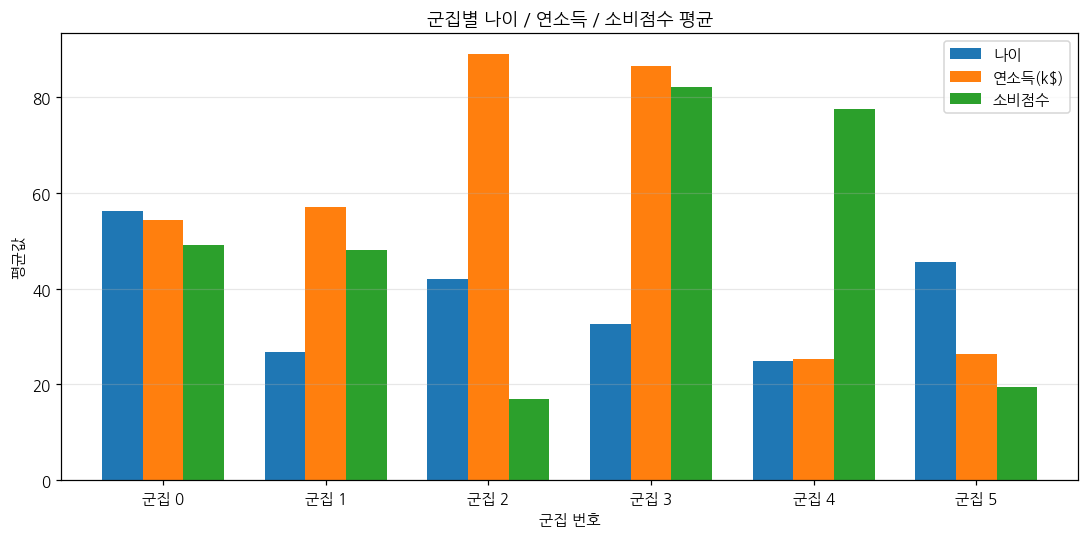

저장 완료: cluster_profile_bar.png


In [12]:
# 군집별 평균을 막대그래프로 비교
plot_df = cluster_profile[["평균_나이", "평균_연소득_k", "평균_소비점수"]]

fig, ax = plt.subplots(figsize=(10, 5))
plot_df.plot(kind="bar", ax=ax, width=0.75)
ax.set_title("군집별 나이 / 연소득 / 소비점수 평균")
ax.set_xlabel("군집 번호")
ax.set_ylabel("평균값")
ax.set_xticklabels([f"군집 {i}" for i in plot_df.index], rotation=0)
ax.legend(["나이", "연소득(k$)", "소비점수"])
ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
bar_path = BASE_DIR / "cluster_profile_bar.png"
fig.savefig(bar_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"저장 완료: {bar_path.name}")


## 11단계. 군집별 특성 설명과 고객 유형명 제안

아래 이름은 **우열 순위가 아닙니다.**  
전체 평균(나이 약 38.9세, 소득 약 60.6k, 소비점수 약 50.2)과 비교해 붙인 실무용 별명입니다.


In [13]:
def suggest_persona(row, overall_row):
    '''평균 대비 높음/낮음 패턴으로 유형명을 제안합니다.'''
    age = row["평균_나이"]
    income = row["평균_연소득_k"]
    score = row["평균_소비점수"]

    age_mean = overall_row["평균_나이"]
    income_mean = overall_row["평균_연소득_k"]
    score_mean = overall_row["평균_소비점수"]

    high_income = income >= income_mean + 10
    low_income = income <= income_mean - 10
    high_score = score >= score_mean + 10
    low_score = score <= score_mean - 10
    older = age >= age_mean + 8
    younger = age <= age_mean - 8

    if high_income and high_score:
        return "프리미엄 핵심 고객"
    if high_income and low_score:
        return "고소득 저소비 신중 고객"
    if low_income and high_score:
        return "트렌드 추종형 청년 고객"
    if low_income and low_score:
        return "가격민감 절약 고객"
    if older:
        return "안정형 중장년 고객"
    if younger:
        return "균형형 청년 고객"
    return "평균형 일반 고객"


persona_rows = []
overall_row = overall.iloc[0]
for cluster_id, row in cluster_profile.iterrows():
    name = suggest_persona(row, overall_row)
    persona_rows.append(
        {
            "군집": cluster_id,
            "고객 유형명": name,
            "고객수": int(row["고객수"]),
            "평균 나이": round(row["평균_나이"], 1),
            "평균 연소득(k$)": round(row["평균_연소득_k"], 1),
            "평균 소비점수": round(row["평균_소비점수"], 1),
        }
    )

persona_df = pd.DataFrame(persona_rows).set_index("군집")
display(persona_df)

# 이후 저장/보고서에 쓰기 위해 매핑을 보관합니다.
cluster_name_map = persona_df["고객 유형명"].to_dict()
df["SegmentName"] = df["Cluster"].map(cluster_name_map)

print("\n[유형 해석]")
for cluster_id, row in persona_df.iterrows():
    print(
        f"- 군집 {cluster_id} '{row['고객 유형명']}' "
        f"(n={row['고객수']}): 나이 {row['평균 나이']}세, "
        f"소득 {row['평균 연소득(k$)']}k, 소비점수 {row['평균 소비점수']}"
    )


,고객 유형명,고객수,평균 나이,평균 연소득(k$),평균 소비점수
군집,,,,,
0,안정형 중장년 고객,45,56.30,54.30,49.10
1,균형형 청년 고객,39,26.80,57.10,48.10
2,고소득 저소비 신중 고객,33,41.90,88.90,17.00
3,프리미엄 핵심 고객,39,32.70,86.50,82.10
4,트렌드 추종형 청년 고객,23,25.00,25.30,77.60
5,가격민감 절약 고객,21,45.50,26.30,19.40



[유형 해석]
- 군집 0 '안정형 중장년 고객' (n=45): 나이 56.3세, 소득 54.3k, 소비점수 49.1
- 군집 1 '균형형 청년 고객' (n=39): 나이 26.8세, 소득 57.1k, 소비점수 48.1
- 군집 2 '고소득 저소비 신중 고객' (n=33): 나이 41.9세, 소득 88.9k, 소비점수 17.0
- 군집 3 '프리미엄 핵심 고객' (n=39): 나이 32.7세, 소득 86.5k, 소비점수 82.1
- 군집 4 '트렌드 추종형 청년 고객' (n=23): 나이 25.0세, 소득 25.3k, 소비점수 77.6
- 군집 5 '가격민감 절약 고객' (n=21): 나이 45.5세, 소득 26.3k, 소비점수 19.4


### 데이터에 근거한 유형 설명 (K=6, random_state=42 기준)

| 군집 | 제안 유형명 | 데이터 근거 | 기획 포인트 |
|------|-------------|-------------|-------------|
| 0 | 안정형 중장년 고객 | 나이 높음(약 56세), 소득·소비는 평균 근처 | 기본 상품·멤버십 유지, 과한 트렌드 메시지보다 신뢰 |
| 1 | 균형형 청년 고객 | 나이 낮음(약 27세), 소득·소비 모두 평균 | 입문 상품, 앱 혜택, 라이프스타일 콘텐츠 |
| 2 | 고소득 저소비 신중 고객 | 소득 매우 높음, 소비점수는 매우 낮음 | **전환 기회**. 가치·품질 소구, 맞춤 컨시어지 |
| 3 | 프리미엄 핵심 고객 | 소득·소비 모두 높음, 30대 초반 | VIP 프로그램, 신상품 우선 제안 |
| 4 | 트렌드 추종형 청년 고객 | 소득은 낮지만 소비점수는 높음 | 가성비·프로모션, 소액 고빈도 상품 |
| 5 | 가격민감 절약 고객 | 소득·소비 모두 낮음, 중장년 | 할인·필수재 중심, 무리한 업셀 지양 |

다시 강조하면, **군집 5가 군집 3보다 가치가 낮다**고 단정할 수 없습니다.  
절약형 고객도 필수 상품의 안정 수요가 될 수 있고, 고소득 저소비 고객은 아직 지출을 안 했을 뿐입니다.


## 12단계. 분석 결과 CSV 저장

원본 컬럼 + 군집 번호 + 유형명 + PCA 좌표를 저장합니다.  
엑셀에서 열려면 `utf-8-sig` 인코딩을 사용합니다.


In [14]:
result_df = df[
    [
        "CustomerID",
        "Gender",
        "Age",
        "Annual Income (k$)",
        "Spending Score (1-100)",
        "Cluster",
        "SegmentName",
        "PC1",
        "PC2",
    ]
].sort_values("CustomerID")

csv_path = BASE_DIR / "customer_cluster_results.csv"
result_df.to_csv(csv_path, index=False, encoding="utf-8-sig")

print(f"저장 완료: {csv_path.resolve()}")
print(f"저장 행 수: {len(result_df)}")
display(result_df.head(10))


저장 완료: /content/customer_cluster_results.csv
저장 행 수: 200


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,SegmentName,PC1,PC2
0,1,Male,19,15,39,4,트렌드 추종형 청년 고객,-0.62,-1.76
1,2,Male,21,15,81,4,트렌드 추종형 청년 고객,-1.67,-1.82
2,3,Female,20,16,6,5,가격민감 절약 고객,0.34,-1.67
3,4,Female,23,16,77,4,트렌드 추종형 청년 고객,-1.46,-1.77
4,5,Female,31,17,40,5,가격민감 절약 고객,-0.04,-1.66
5,6,Female,22,17,76,4,트렌드 추종형 청년 고객,-1.48,-1.74
6,7,Female,35,18,6,5,가격민감 절약 고객,1.09,-1.57
7,8,Female,23,18,94,4,트렌드 추종형 청년 고객,-1.93,-1.72
8,9,Male,64,19,3,5,가격민감 절약 고객,2.65,-1.46
9,10,Female,30,19,72,4,트렌드 추종형 청년 고객,-0.97,-1.64


## 13단계. 주요 그래프 PNG 저장 확인

앞에서 이미 저장한 파일입니다.

- `elbow_silhouette_plot.png` : 엘보우 + 실루엣
- `pca_cluster_scatter.png` : PCA 군집 산점도
- `cluster_profile_bar.png` : 군집별 평균 막대그래프


In [15]:
saved_files = [
    BASE_DIR / "elbow_silhouette_plot.png",
    BASE_DIR / "pca_cluster_scatter.png",
    BASE_DIR / "cluster_profile_bar.png",
    BASE_DIR / "customer_cluster_results.csv",
]

print("산출물 확인")
for path in saved_files:
    status = "있음" if path.exists() else "없음"
    size = f"{path.stat().st_size:,} bytes" if path.exists() else "-"
    print(f"- [{status}] {path.name:32s} {size}")


산출물 확인
- [있음] elbow_silhouette_plot.png        77,933 bytes
- [있음] pca_cluster_scatter.png          116,924 bytes
- [있음] cluster_profile_bar.png          31,116 bytes
- [있음] customer_cluster_results.csv     17,686 bytes


## AI 서비스 기획 관점의 결과 해석 보고서

### 1) 이 분석이 기획에 주는 의미

쇼핑몰을 “평균 고객 한 명”에게 맞춰 운영하면, VIP와 가격민감 고객에게 같은 메시지를 보내게 됩니다.  
비지도학습 세분화는 **정답이 없는 고객 데이터에서 자연스러운 그룹**을 찾아, 서비스 기능과 캠페인을 나누기 위한 출발점입니다.

### 2) 세그먼트별 서비스 아이디어

| 고객 유형 | 서비스/기능 가설 | 성공 지표 예시 |
|-----------|------------------|----------------|
| 프리미엄 핵심 고객 | VIP 등급, 신상품 선공개, 1:1 추천 | 객단가, 재구매, VIP 유지율 |
| 고소득 저소비 신중 고객 | 품질 스토리, 체험 키트, 상담 예약 | 첫 구매 전환율, 카테고리 확대 |
| 트렌드 추종형 청년 | 타임세일, 소셜 증명, 소액 구독 | 구매 빈도, 앱 재방문 |
| 균형형 청년 | 온보딩 쿠폰, 취향 퀴즈 추천 | 가입 후 첫 구매 기간 |
| 안정형 중장년 | 심플 UX, 정기배송, 신뢰 리뷰 | 이탈률, 정기배송 유지 |
| 가격민감 절약 고객 | 가격 비교, 쿠폰 자동 적용 | 쿠폰 사용률, 필수 카테고리 매출 |

### 3) 제품에 바로 넣을 수 있는 기능 초안

1. **세그먼트 대시보드** : 오늘 방문 고객의 군집 분포와 전주 대비 변화  
2. **개인화 홈 배너** : 같은 앱이라도 군집마다 다른 메인 카드  
3. **캠페인 가드레일** : 절약형 고객에게 고가 상품 푸시를 제한  
4. **VIP 케어 큐** : 프리미엄 군집의 장바구니 이탈 시 상담 우선 배정  
5. **전환 실험** : 고소득 저소비 군집만 대상으로 A/B 테스트

### 4) 기획자가 조심할 점

- 군집 번호는 등급이 아닙니다. UI에 “Cluster 3 = 우수”처럼 붙이지 마세요.
- 현재 변수는 나이·소득·소비점수 3개뿐입니다. 실제 서비스에서는 최근성(Recency), 구매빈도, 카테고리, 채널 반응을 추가하는 것이 좋습니다.
- PCA 2차원은 시각화용입니다. 정보 약 22%는 압축 과정에서 빠집니다(PC1+PC2 ≈ 77.6%).
- 이 결과는 200명 샘플·특정 난수 시드 기준입니다. 고객이 늘면 K와 유형명이 달라질 수 있습니다.
- 성별은 학습에 넣지 않았습니다. 성별 타깃팅을 할 때는 별도 공정성 검토가 필요합니다.

### 5) 다음 실험 제안

1. K=5와 K=6 세그먼트로 이메일 캠페인을 나눠 클릭률을 비교한다.  
2. “고소득 저소비” 군집에게 할인 메시지 vs 품질 메시지 A/B 테스트.  
3. 3개월 후 같은 고객의 군집 이동을 추적해, 세그먼트가 안정적인지 본다.
